# Hi-C consensus geometry: five yeast chromosomes


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：yeast_hic_consensus_geometry

**观测 y：** contact_counts(1, 350, 350)；bead_support(1, 350)；chromosome_index(1, 350)；locus_bounds(1, 350, 2)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 染色体350bin三维共识坐标。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 接触计数Poisson均值依赖校正后粒子距离幂律。本地路径为 `solvers.reconstruct→ICE→fit_pm1`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 5, 7, 8, 10, 11, 13（cell编号按文件内从0计）。章节包括：# Hi-C consensus geometry: five yeast chromosomes；## 2. Data；## 3. Physics and identifiability；## 4. Method and independent original comparison；## 5. Results, residuals and active perturbations；The complete geometry views above retain long-excursion loci. The following supplementary **display-only** window expands the central cluster for legibility. All343 supported coordinates are still plotted and scored; the visible window is explicitly limited to±0.5model units on each globally aligned axis. No displayed-window support replaces the measurement mask or any acceptance metric. The source's extreme visibility and long inferred excursions remain an identifiability warning, rather than a biological claim about stretched chromosomes.；## 6. Conclusion and scope。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 无独立生物几何GT；零计数不计似然和不可辨认位置必须说明。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem
Chromosome-conformation measurements count cross-linked, ligated DNA fragment pairs. We infer a **consensus three-dimensional locus geometry**, not a single-cell trajectory or independently measured molecular coordinates. The bound author-supplied real sample contains the complete first five chromosome example: 350 genomic bins, 343 with measured contacts. All supplied loci remain in optimization; seven unobserved bins are zero padding only at submission.

The primary estimator is the original positive-pair Poisson PM1 configuration. Every fresh result below is computed from the public raw counts by local mathematical modules. Original-run measurements are explicitly labeled. A method reference establishes implementation agreement; it cannot establish biological truth.

In [1]:
import os,sys,time,json,hashlib,platform
from pathlib import Path
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.generate_data import retain_contacts
from src.preprocessing import load_data,ice_normalize,build_pairs,aggregate_contacts
from src.physics_model import all_distances,align_for_display,intensity,poisson_objective,pair_distances,wish_distances
from src.solvers import reconstruct,fit_mds,fit_pm1,fit_pm2,fit_nmds
from src.visualization import draw_structure,export_figure
FIGURE_DIR=os.environ.get('IMAGING101_FIGURE_DIR')
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.dpi':110})
raw_hash=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
environment=dict(python=sys.version,numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__,platform=platform.platform(),raw_sha256=raw_hash,threads={k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']})
print(json.dumps(environment,indent=2))
def show(fig,name,sources,caption):
    export_figure(fig,name,sources,dict(caption=caption,provenance='Fresh local mathematics on bound raw counts unless array name identifies original source',environment=environment),FIGURE_DIR)
    plt.show();plt.close(fig)
def center(x,support):
    x=x.copy();x[support]-=x[support].mean(0);x[~support]=0;return x
data=load_data(ROOT/'data/raw_data.npz');counts=data['contact_counts'][0];support=data['bead_support'][0];chrom=data['chromosome_index'][0]
row,col,c=build_pairs(counts);normalized,bias,ice_history=ice_normalize(counts)
refs=ROOT/'notebooks/reference_outputs'
source_pm1=np.load(refs/'upstream_pm1.npz')['coordinates']
source_pm2=np.load(refs/'upstream_pm2.npz')['coordinates']
source_nmds=np.load(refs/'qualified_upstream_nmds.npz')['coordinates']
print('Loci',len(support),'observed',support.sum(),'positive pairs',len(c),'total contacts',int(c.sum()))

{
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "platform": "Windows-10-10.0.26200-SP0",
  "raw_sha256": "8a862c455cb39546ad96a907b98b2e077bc325905ce41f12d248ffa8c1ec2d6b",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}
Loci 350 observed 343 positive pairs 53883 total contacts 1902039


## 2. Data
These are genuine yeast Hi-C contact counts distributed as the authors' `iced` sample, with native 10 kb, one-based inclusive genomic bounds. The five chromosome bin counts are 24, 82, 32, 154 and 58. The array stores each pair once in its strict upper triangle. The matrix is mirrored **only for display**. Zero entries do not enter the selected original PM1 objective. The precise restriction-enzyme library is not identified by this distributed sample; we do not infer it from a related paper.

Visibility correction uses only measured counts. It equalizes nonzero locus marginals while preserving total count, not using reconstructed geometry. The sample is openly offered by the authors for research; a distinct data redistribution license has not been located. Code BSD licenses do not establish data rights.

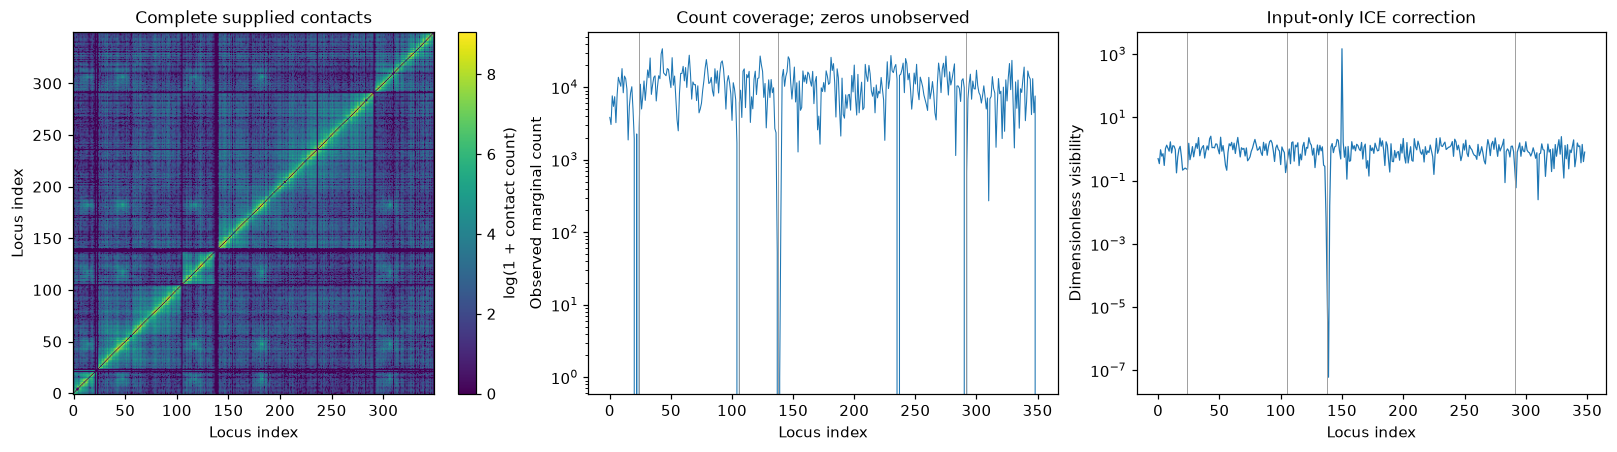

In [2]:
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
image=axes[0].imshow(np.log1p(counts+counts.T),origin='lower',cmap='viridis',rasterized=True);fig.colorbar(image,ax=axes[0],label='log(1 + contact count)');axes[0].set(title='Complete supplied contacts',xlabel='Locus index',ylabel='Locus index')
axes[1].plot(counts.sum(0)+counts.sum(1),lw=.7);axes[1].set(yscale='log',xlabel='Locus index',ylabel='Observed marginal count',title='Count coverage; zeros unobserved')
axes[2].plot(np.flatnonzero(support),bias[support],lw=.8);axes[2].set(xlabel='Locus index',ylabel='Dimensionless visibility',yscale='log',title='Input-only ICE correction')
for ax in axes[1:]:
    for boundary in np.cumsum([24,82,32,154,58])[:-1]:ax.axvline(boundary-.5,color='.6',lw=.6)
show(fig,'fig01_observations',dict(counts=counts,support=support,bias=bias,chromosome=chrom),'Full native350-bin observations; no crop, interpolation or outcome-dependent support.')

## 3. Physics and identifiability
For an observed pair $i,j$, the model is
$$d_{ij}=\|x_i-x_j\|_2,\qquad \lambda_{ij}=b_i b_j\beta d_{ij}^{\alpha},\qquad C_{ij}\sim\operatorname{Poisson}(\lambda_{ij}).$$
Here $x_i$ is a three-component locus coordinate, $C$ is the integer count, $b$ is input-derived visibility, $\lambda$ is expected count, $\alpha=-3$ is the fixed contact-distance exponent and $\beta=1$ fixes the model-distance scale. This scale has **no established conversion to nm**. The fit uses positive stored pairs only, matching the original implementation, rather than claiming that every zero pair is modeled. This is not a zero-truncated Poisson likelihood: no truncation normalization is included.

Translation, rotation and reflection are unidentifiable. All 58,653 distances among supported loci are therefore scored; this preserves cross-chromosome constraints. The Judge performs no scale fit. Globally aligned displays below are explicitly marked; any scale alignment is reserved for comparisons with changed acquisition binning or exponent, never for acceptance.

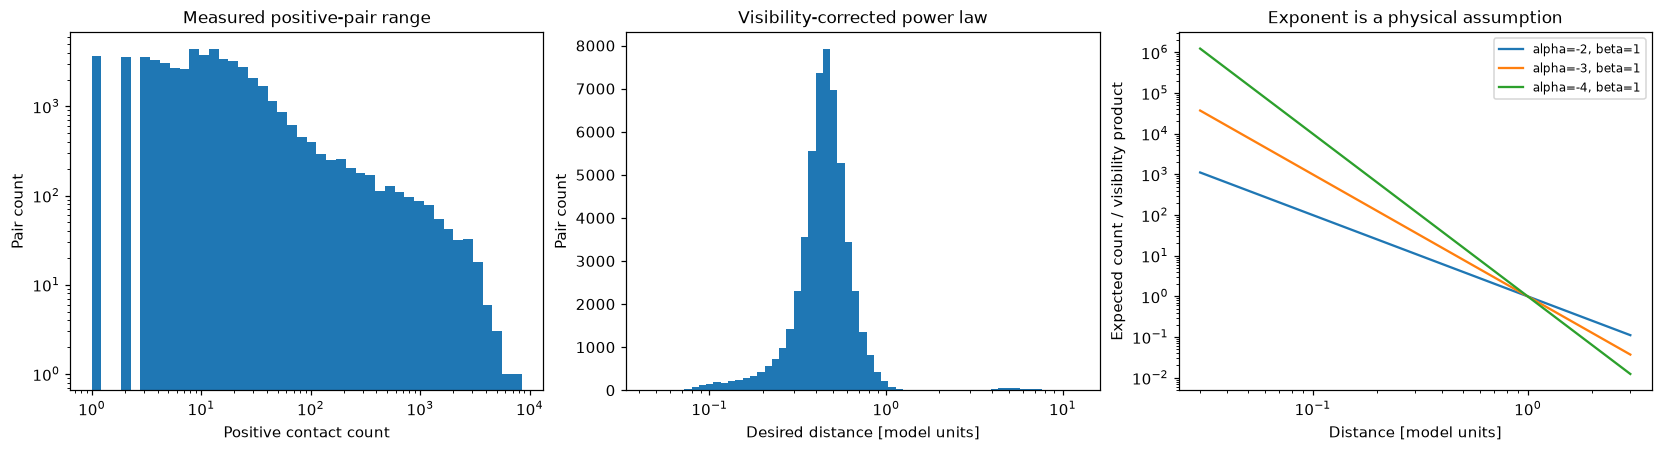

In [3]:
wish=wish_distances(row,col,c,bias)
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
axes[0].hist(c,bins=np.geomspace(1,c.max()+1,45));axes[0].set(xscale='log',yscale='log',xlabel='Positive contact count',ylabel='Pair count',title='Measured positive-pair range')
axes[1].hist(wish,bins=np.geomspace(wish.min(),wish.max(),60));axes[1].set(xscale='log',xlabel='Desired distance [model units]',ylabel='Pair count',title='Visibility-corrected power law')
distance=np.geomspace(.03,3,200)
for exponent in [-2,-3,-4]:axes[2].loglog(distance,distance**exponent,label=f'alpha={exponent}, beta=1')
axes[2].set(xlabel='Distance [model units]',ylabel='Expected count / visibility product',title='Exponent is a physical assumption');axes[2].legend(fontsize=8)
show(fig,'fig02_model',dict(count=c,wish=wish,distance=distance,exponents=np.array([-2,-3,-4])),'Fixed conditional contact law; observed counts constrain geometry statistically, not exact pair distances.')

## 4. Method and independent original comparison
The MDS2 initializer minimizes $S=\sum (d-\delta)^2/\delta^2$, with $\delta=(C/(b_i b_j\beta))^{1/\alpha}$. PM1 then minimizes $L=\sum(\lambda-C\log\lambda)$ over positive pairs. Its pair derivative is $\alpha(\lambda-C)(x_i-x_j)/d^2$. The local code evaluates these formulas and preserves the original per-locus sum order. SciPy supplies the general L-BFGS-B optimizer. Seed0, all350 coordinate slots, source stopping criteria and full5000-iteration limits are retained.

The independently executed unmodified PM1 and PM2 outputs are comparison measurements. The upstream NMDS wrapper fails on an ndarray/string truth-value guard at its second outer iteration; its comparison oracle applies one documented type check and preserves numerical steps. We label this **qualified API-repaired NMDS**, not an unmodified successful run. Original failures and the distinct earlier numerical-backend run are retained privately. Independent gradient, rigid-gauge and profiled-alpha checks precede local extraction.

Fresh PM1 seconds 112.65799459999835 objective -7920610.805626988 stopping CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Fresh PM1 versus independent original {'distance_ncc': 0.9999999999999999, 'distance_nrmse': 6.909064523266302e-18}


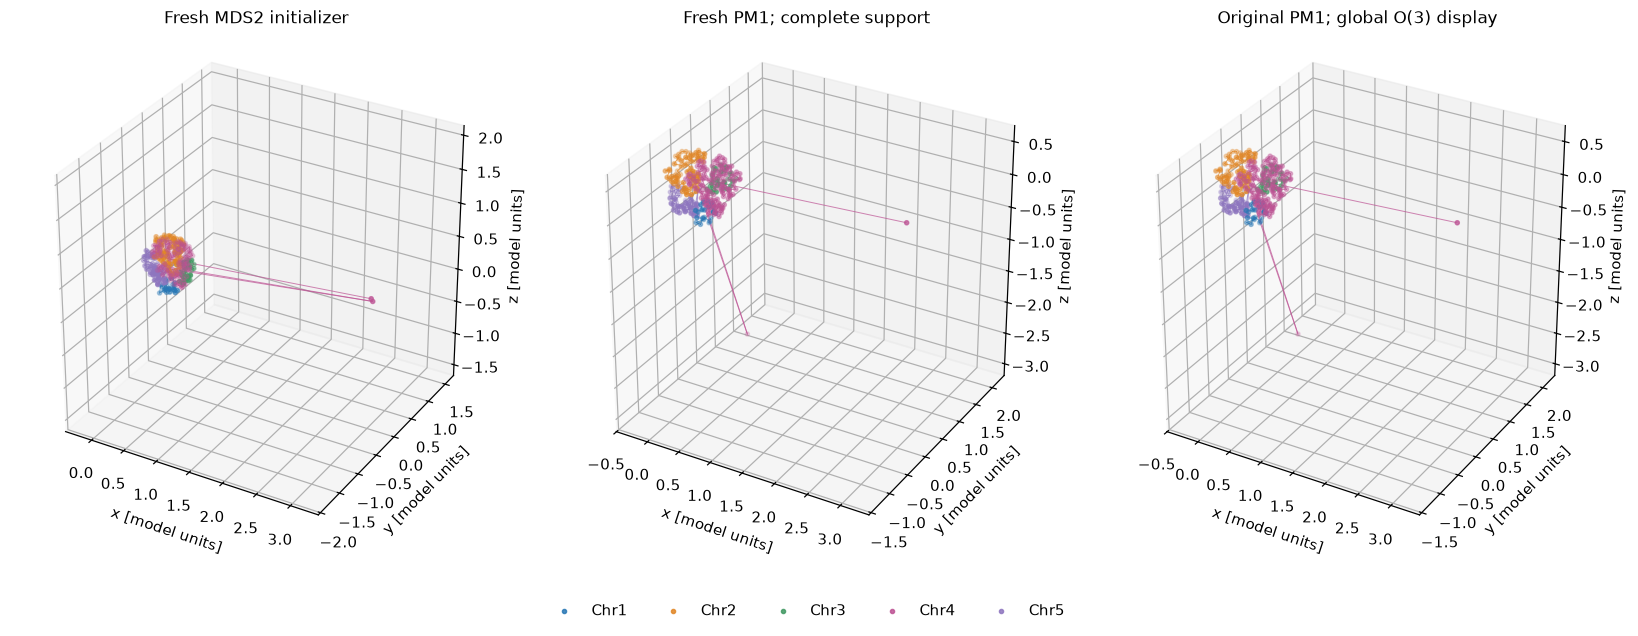

Fresh PM2 409.5117051999987 -1.9641532490255738 2.8588674379756447 {'distance_ncc': 0.9999999999999998, 'distance_nrmse': 0.0}
Fresh qualified NMDS 11.33947600000829 {'distance_ncc': 1.0000000000000002, 'distance_nrmse': 1.964978316722279e-13}


In [4]:
start=time.perf_counter();fresh,diag=reconstruct(data);primary_seconds=time.perf_counter()-start
x=fresh[0];mds=center(diag['initial_coordinates'],support)
print('Fresh PM1 seconds',primary_seconds,'objective',diag['objective'],'stopping',diag['stop'])
def geometry_metrics(a,b,m=support):
    da=all_distances(a,m);db=all_distances(b,m)
    return dict(distance_ncc=float(da@db/np.linalg.norm(da)/np.linalg.norm(db)),distance_nrmse=float(np.sqrt(np.mean((da-db)**2))/np.ptp(db)))
print('Fresh PM1 versus independent original',geometry_metrics(x,source_pm1))
source_view,_=align_for_display(source_pm1,x,support)
fig=plt.figure(figsize=(15,5),layout='constrained')
for index,(coordinates,label) in enumerate([(mds,'Fresh MDS2 initializer'),(x,'Fresh PM1; complete support'),(source_view,'Original PM1; global O(3) display')]):draw_structure(fig.add_subplot(1,3,index+1,projection='3d'),coordinates,support,chrom,label)
show(fig,'fig03_primary_geometry',dict(fresh_pm1=x,fresh_mds=mds,original_pm1=source_pm1,aligned_original=source_view,support=support,chromosome=chrom),'All343 observed loci across five chromosomes; lines connect only adjacent supported native bins; no physical nm scale.')
start=time.perf_counter();pm2,pm2diag=fit_pm2(counts,bias);pm2_seconds=time.perf_counter()-start
start=time.perf_counter();nmds,nmdsdiag=fit_nmds(counts,bias);nmds_seconds=time.perf_counter()-start
print('Fresh PM2',pm2_seconds,pm2diag['alpha'],pm2diag['beta'],geometry_metrics(pm2,source_pm2))
print('Fresh qualified NMDS',nmds_seconds,geometry_metrics(nmds,source_nmds))

Columns: own-law positive-pair loss, display-aligned distance NRMSE versus PM1, display scale
{'MDS2': [-5690172.705987056, 0.03416669521002468, 1.0], 'PM1': [-7920610.805626988, 2.5951289434799065e-17, 1.0], 'PM2': [-8174565.670789196, 0.06777923417382807, 0.5289303098297968], 'NMDS (API repair)': [84455552.97981344, 0.0715122064112576, 1.0]}


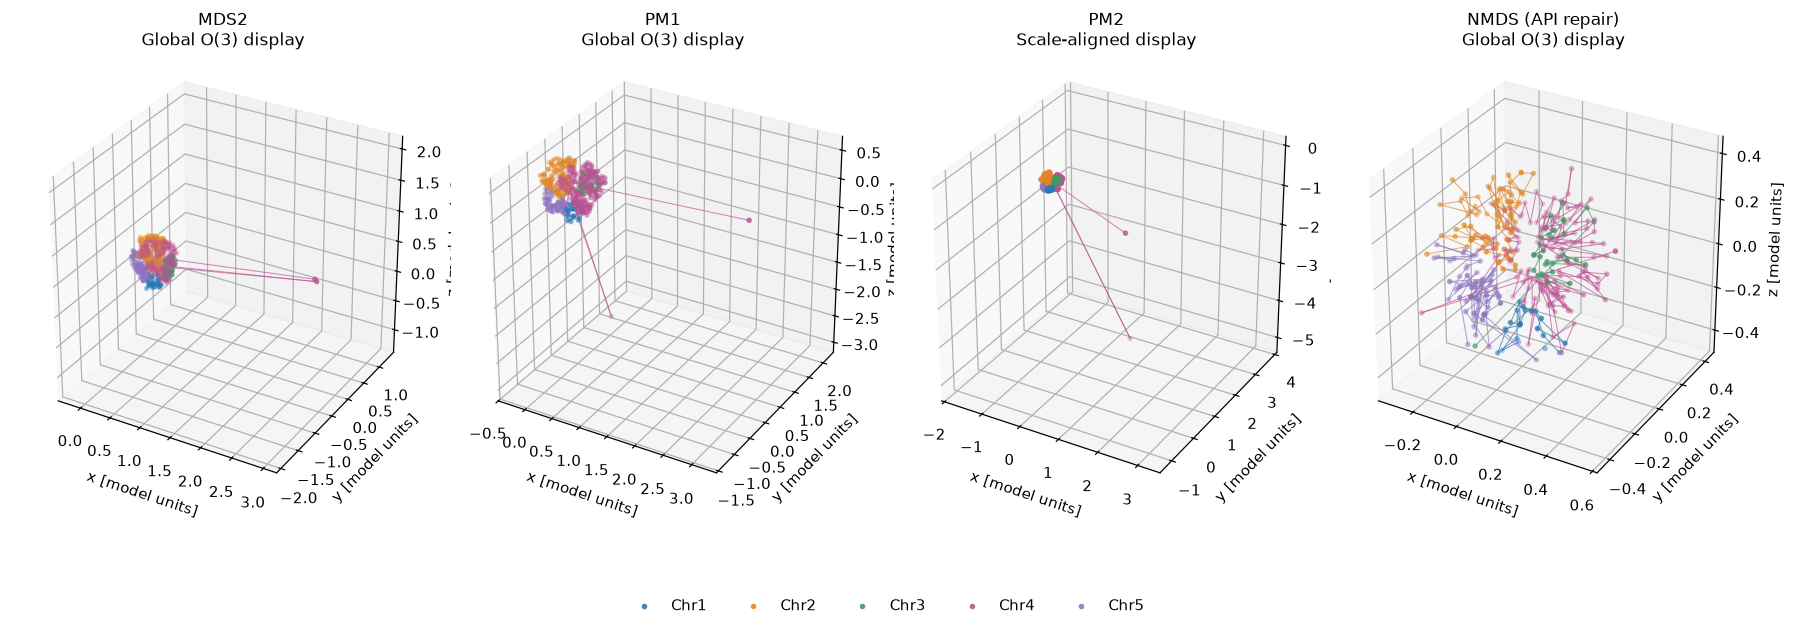

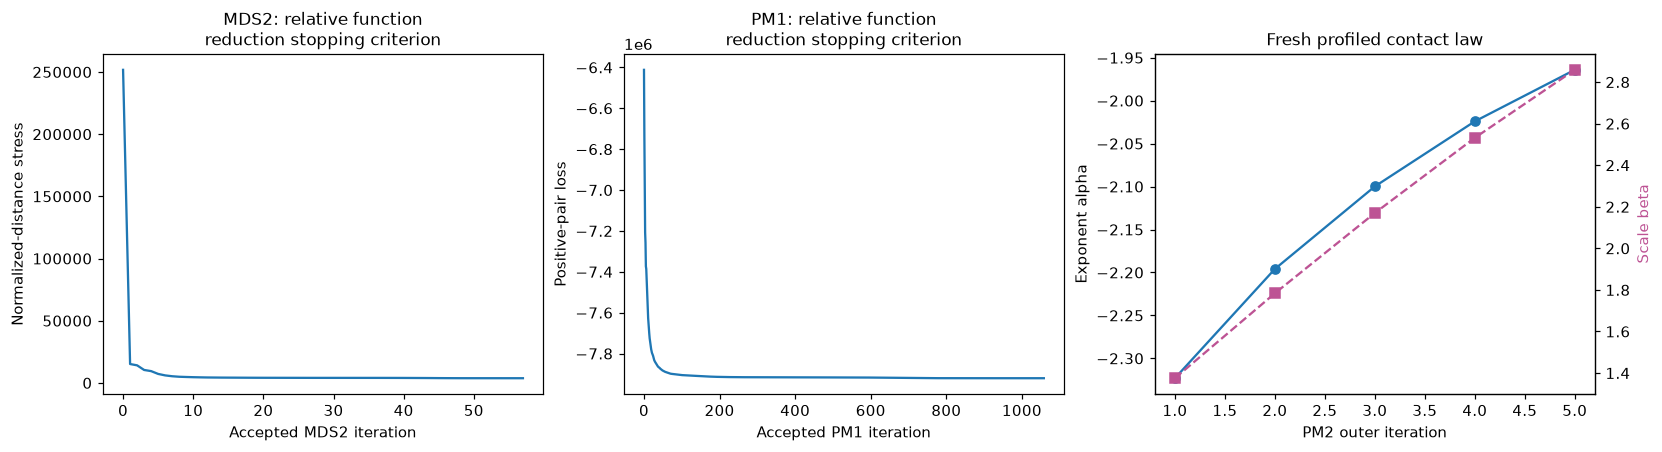

In [5]:
methods={'MDS2':mds,'PM1':x,'PM2':pm2,'NMDS (API repair)':nmds}
fig=plt.figure(figsize=(16,5),layout='constrained')
comparison_rows=[]
for k,(name,coordinates) in enumerate(methods.items()):
    display,scale=align_for_display(coordinates,x,support,allow_scale=name=='PM2')
    title=name+ ('\nScale-aligned display' if name=='PM2' else '\nGlobal O(3) display')
    draw_structure(fig.add_subplot(1,4,k+1,projection='3d'),display,support,chrom,title)
    lawalpha=pm2diag['alpha'] if name=='PM2' else -3.;lawbeta=pm2diag['beta'] if name=='PM2' else 1.
    comparison_rows.append([poisson_objective(coordinates,row,col,c,bias,lawalpha,lawbeta),geometry_metrics(display,x)['distance_nrmse'],scale])
print('Columns: own-law positive-pair loss, display-aligned distance NRMSE versus PM1, display scale')
print(dict(zip(methods,comparison_rows)))
show(fig,'fig04_actual_method_comparison',dict(mds=mds,pm1=x,pm2=pm2,nmds=nmds,comparison_table=np.array(comparison_rows),pm2_alpha_beta=np.array([pm2diag['alpha'],pm2diag['beta']]),support=support,chromosome=chrom),'All four supported paper-family methods computed freshly; changed exponent/scale PM2 shown with declared global similarity display only. No independent spatial truth.')
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
axes[0].plot(diag['mds']['history']);axes[0].set(xlabel='Accepted MDS2 iteration',ylabel='Normalized-distance stress',title='MDS2: relative function\nreduction stopping criterion')
axes[1].plot(diag['history']);axes[1].set(xlabel='Accepted PM1 iteration',ylabel='Positive-pair loss',title='PM1: relative function\nreduction stopping criterion')
outer=pm2diag['outer_history'];axes[2].plot(np.arange(1,6),outer[:,0],'o-',label='Fitted exponent');axes[2].set(xlabel='PM2 outer iteration',ylabel='Exponent alpha',title='Fresh profiled contact law');twin=axes[2].twinx();twin.plot(np.arange(1,6),outer[:,1],'s--',color='#bd5394');twin.set_ylabel('Scale beta',color='#bd5394')
show(fig,'fig05_optimization',dict(mds_history=diag['mds']['history'],pm1_history=diag['history'],pm2_outer_history=outer),'Actual callback histories and stopping messages; objective stationarity does not establish biological accuracy.')

## 5. Results, residuals and active perturbations
There are no independently measured coordinates for this sample. The method-reference score is therefore reported alongside count-domain diagnostics and actual perturbation experiments. A Poisson deviance is $D=2\sum[C\log(C/\lambda)-(C-\lambda)]$ on the positive pairs. A simple no-geometry comparator assigns one common distance while retaining visibility, with total predicted count matched. This comparison checks whether inferred spatial structure improves the measured-count fit; it does not validate a physical ground truth.

The following count-retention experiment is **simulated thinning of real counts**, not an independent biological replicate. It keeps the entire native locus set. Genomic aggregation preserves all source bins within each chromosome and discards only contacts internal to a new bin. Resolution/exponent comparisons explicitly allow one global scale fit for display and stability measurement because those configurations change model-distance units; the primary Judge never does.

No hidden truth; positive-pair deviance [14531104.38085829   743351.30062943] signal L2 residual 0.24807769768408147


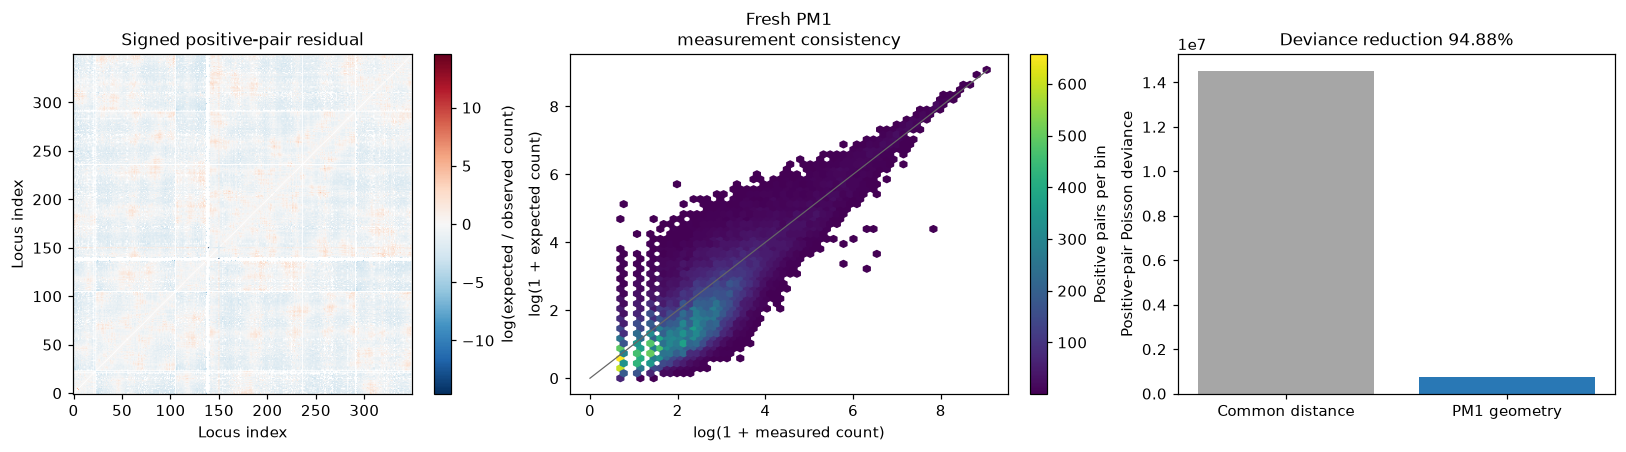

Simulated count retention [0.5, 342, 0.8145282257166695, 0.05456444467621361, 78.56355139998777] original-support scoring 343
Simulated count retention [0.2, 342, 0.5565602677132118, 0.06179379281133116, 58.265501500005485] original-support scoring 343


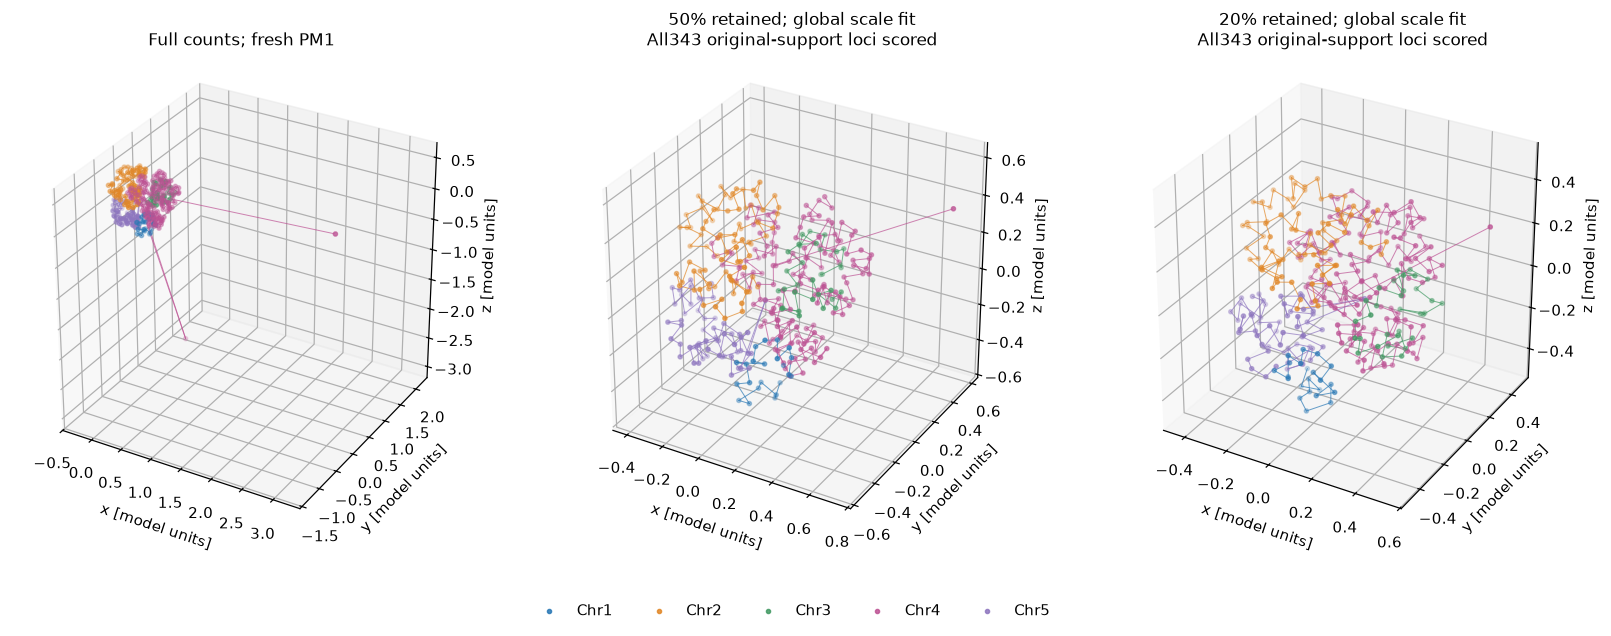

In [6]:
lam=intensity(x,row,col,bias);null=bias[row]*bias[col];null*=c.sum()/null.sum()
def deviance(expected):return float(2*np.sum(c*np.log(c/expected)-(c-expected)))
deviances=np.array([deviance(null),deviance(lam)])
residual=np.full(counts.shape,np.nan);residual[row,col]=np.log(lam/c);residual[col,row]=residual[row,col]
limit=float(np.nanmax(np.abs(residual)))
fig,axes=plt.subplots(1,3,figsize=(15,4),layout='constrained')
im=axes[0].imshow(residual,origin='lower',cmap='RdBu_r',vmin=-limit,vmax=limit,rasterized=True);fig.colorbar(im,ax=axes[0],label='log(expected / observed count)');axes[0].set(title='Signed positive-pair residual',xlabel='Locus index',ylabel='Locus index')
bins=axes[1].hexbin(np.log1p(c),np.log1p(lam),gridsize=55,mincnt=1,cmap='viridis',rasterized=True);fig.colorbar(bins,ax=axes[1],label='Positive pairs per bin');maximum=max(np.log1p(c).max(),np.log1p(lam).max());axes[1].plot([0,maximum],[0,maximum],color='.4',lw=.8);axes[1].set(xlabel='log(1 + measured count)',ylabel='log(1 + expected count)',title='Fresh PM1\nmeasurement consistency')
axes[2].bar(['Common distance','PM1 geometry'],deviances,color=['.65','#2978b5']);axes[2].set(ylabel='Positive-pair Poisson deviance',title=f'Deviance reduction {100*(1-deviances[1]/deviances[0]):.2f}%')
print('No hidden truth; positive-pair deviance',deviances,'signal L2 residual',np.linalg.norm(lam-c)/np.linalg.norm(c))
show(fig,'fig06_count_residuals',dict(observed_counts=c,expected_counts=lam,null_expected=null,residual_matrix=residual,deviances=deviances),'Signed residuals use a symmetric zero-neutral scale; absent pairs are blank, because the selected likelihood excludes zeros.')
thin_results=[];thin_coordinates=[]
for probability in [.5,.2]:
    thinned=retain_contacts(counts,probability,seed=0);thin_support=thinned.sum(0)+thinned.sum(1)>0
    _,thin_bias,_=ice_normalize(thinned)
    start=time.perf_counter();xt,dt=fit_pm1(thinned,thin_bias);elapsed=time.perf_counter()-start
    shared=support&thin_support
    # Quantitative comparison includes every originally supported locus; lost-support values are not silently removed.
    aligned,scale=align_for_display(xt,x,support,allow_scale=True)
    metric=geometry_metrics(aligned,x)
    thin_results.append([probability,int(thin_support.sum()),scale,metric['distance_nrmse'],elapsed]);thin_coordinates.append(aligned)
    print('Simulated count retention',thin_results[-1],'original-support scoring',support.sum())
fig=plt.figure(figsize=(15,5),layout='constrained')
draw_structure(fig.add_subplot(1,3,1,projection='3d'),x,support,chrom,'Full counts; fresh PM1')
for k,(coordinates,result) in enumerate(zip(thin_coordinates,thin_results)):
    draw_structure(fig.add_subplot(1,3,k+2,projection='3d'),coordinates,support,chrom,f'{result[0]:.0%} retained; global scale fit\nAll343 original-support loci scored')
show(fig,'fig07_count_retention',dict(full=x,retained_coordinates=np.asarray(thin_coordinates),table=np.asarray(thin_results),support=support,chromosome=chrom),'Actual binomial thinning seed0 of real counts, not real independent replicates. Table columns: retention, observed support, display scale, full original-support distance NRMSE, runtime seconds.')

Columns factor, total bins, supported bins, discarded within-bin contacts, scale, distance NRMSE, seconds [[2, 175, 175, 231979, 0.8798174905389167, 0.07404920009001263, 13.695339899990358], [4, 89, 89, 504036, 1.9742970148025583, 0.13985040632565202, 1.2752293999947142]]


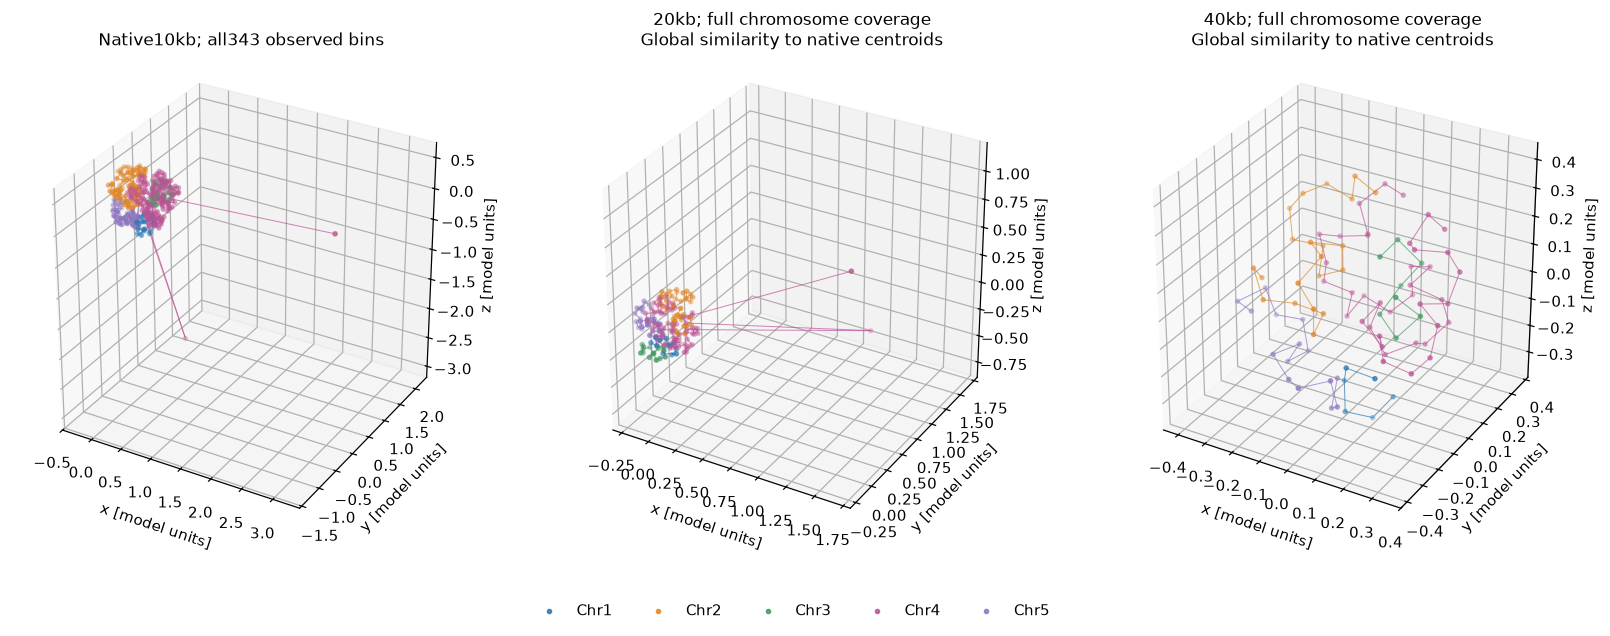

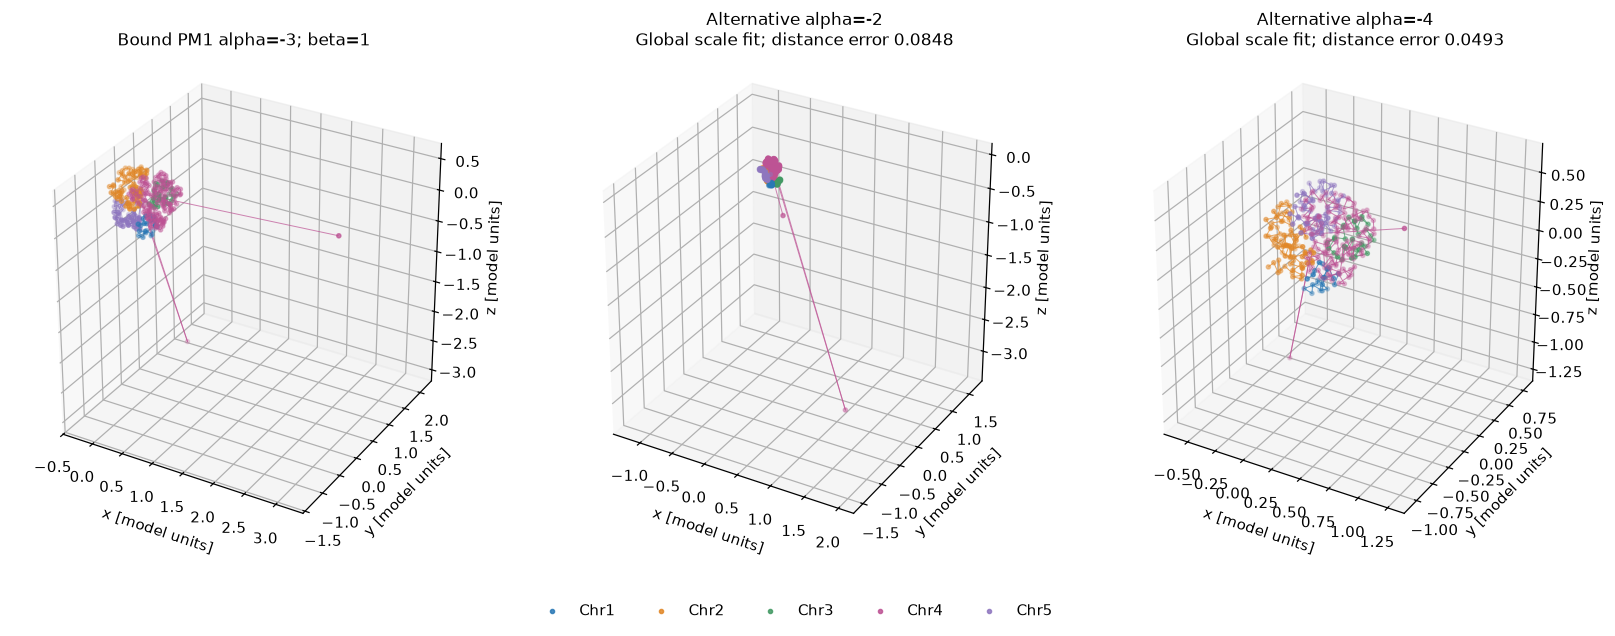

In [7]:
coarse_results=[];coarse_arrays={}
fig=plt.figure(figsize=(15,5),layout='constrained')
draw_structure(fig.add_subplot(1,3,1,projection='3d'),x,support,chrom,'Native10kb; all343 observed bins')
for k,factor in enumerate([2,4]):
    cc,ch,mapping,lost=aggregate_contacts(counts,chrom,factor);cm=cc.sum(0)+cc.sum(1)>0
    _,cb,_=ice_normalize(cc);start=time.perf_counter();cx,cd=fit_pm1(cc,cb);elapsed=time.perf_counter()-start
    centroid=np.zeros_like(cx);centroid_support=np.zeros(len(cx),bool)
    for j in range(len(cx)):
        indices=(mapping==j)&support
        if indices.any():centroid[j]=x[indices].mean(0);centroid_support[j]=True
    compare=cm&centroid_support;aligned,scale=align_for_display(cx,centroid,compare,allow_scale=True)
    metric=geometry_metrics(aligned,centroid,compare)
    coarse_results.append([factor,len(cx),int(cm.sum()),lost,scale,metric['distance_nrmse'],elapsed])
    coarse_arrays.update({f'factor{factor}_counts':cc,f'factor{factor}_mapping':mapping,f'factor{factor}_coordinates':cx,f'factor{factor}_centroids':centroid,f'factor{factor}_aligned':aligned})
    draw_structure(fig.add_subplot(1,3,k+2,projection='3d'),aligned,compare,ch,f'{factor*10}kb; full chromosome coverage\nGlobal similarity to native centroids')
print('Columns factor, total bins, supported bins, discarded within-bin contacts, scale, distance NRMSE, seconds',coarse_results)
show(fig,'fig08_genomic_resolution',dict(native=x,table=np.array(coarse_results),**coarse_arrays),'Actually refitted coarser acquisition representation. Fine-bin centroids are a stability comparator, never a physical truth; one global similarity gauge is declared.')
exponent_results=[];exponent_coordinates=[]
for exponent in [-2.,-4.]:
    start=time.perf_counter();xe,de=fit_pm1(counts,bias,alpha=exponent);elapsed=time.perf_counter()-start
    aligned,scale=align_for_display(xe,x,support,allow_scale=True);metric=geometry_metrics(aligned,x)
    exponent_results.append([exponent,scale,metric['distance_nrmse'],elapsed]);exponent_coordinates.append(aligned)
fig=plt.figure(figsize=(15,5),layout='constrained')
draw_structure(fig.add_subplot(1,3,1,projection='3d'),x,support,chrom,'Bound PM1 alpha=-3; beta=1')
for k,(coordinates,result) in enumerate(zip(exponent_coordinates,exponent_results)):
    draw_structure(fig.add_subplot(1,3,k+2,projection='3d'),coordinates,support,chrom,f'Alternative alpha={result[0]:.0f}\nGlobal scale fit; distance error {result[2]:.3g}')
show(fig,'fig09_exponent_sensitivity',dict(primary=x,alternatives=np.asarray(exponent_coordinates),table=np.array(exponent_results),support=support,chromosome=chrom),'Active model sensitivity; alternatives are not the benchmark estimator and are not judged as physical truth. Columns exponent, display scale, distance NRMSE, seconds.')

The complete geometry views above retain long-excursion loci. The following supplementary **display-only** window expands the central cluster for legibility. All343 supported coordinates are still plotted and scored; the visible window is explicitly limited to±0.5model units on each globally aligned axis. No displayed-window support replaces the measurement mask or any acceptance metric. The source's extreme visibility and long inferred excursions remain an identifiability warning, rather than a biological claim about stretched chromosomes.

Coordinates within display window (all343 still scored): {'MDS2': 341, 'PM1': 319, 'PM2': 341, 'NMDS (API repair)': 342}


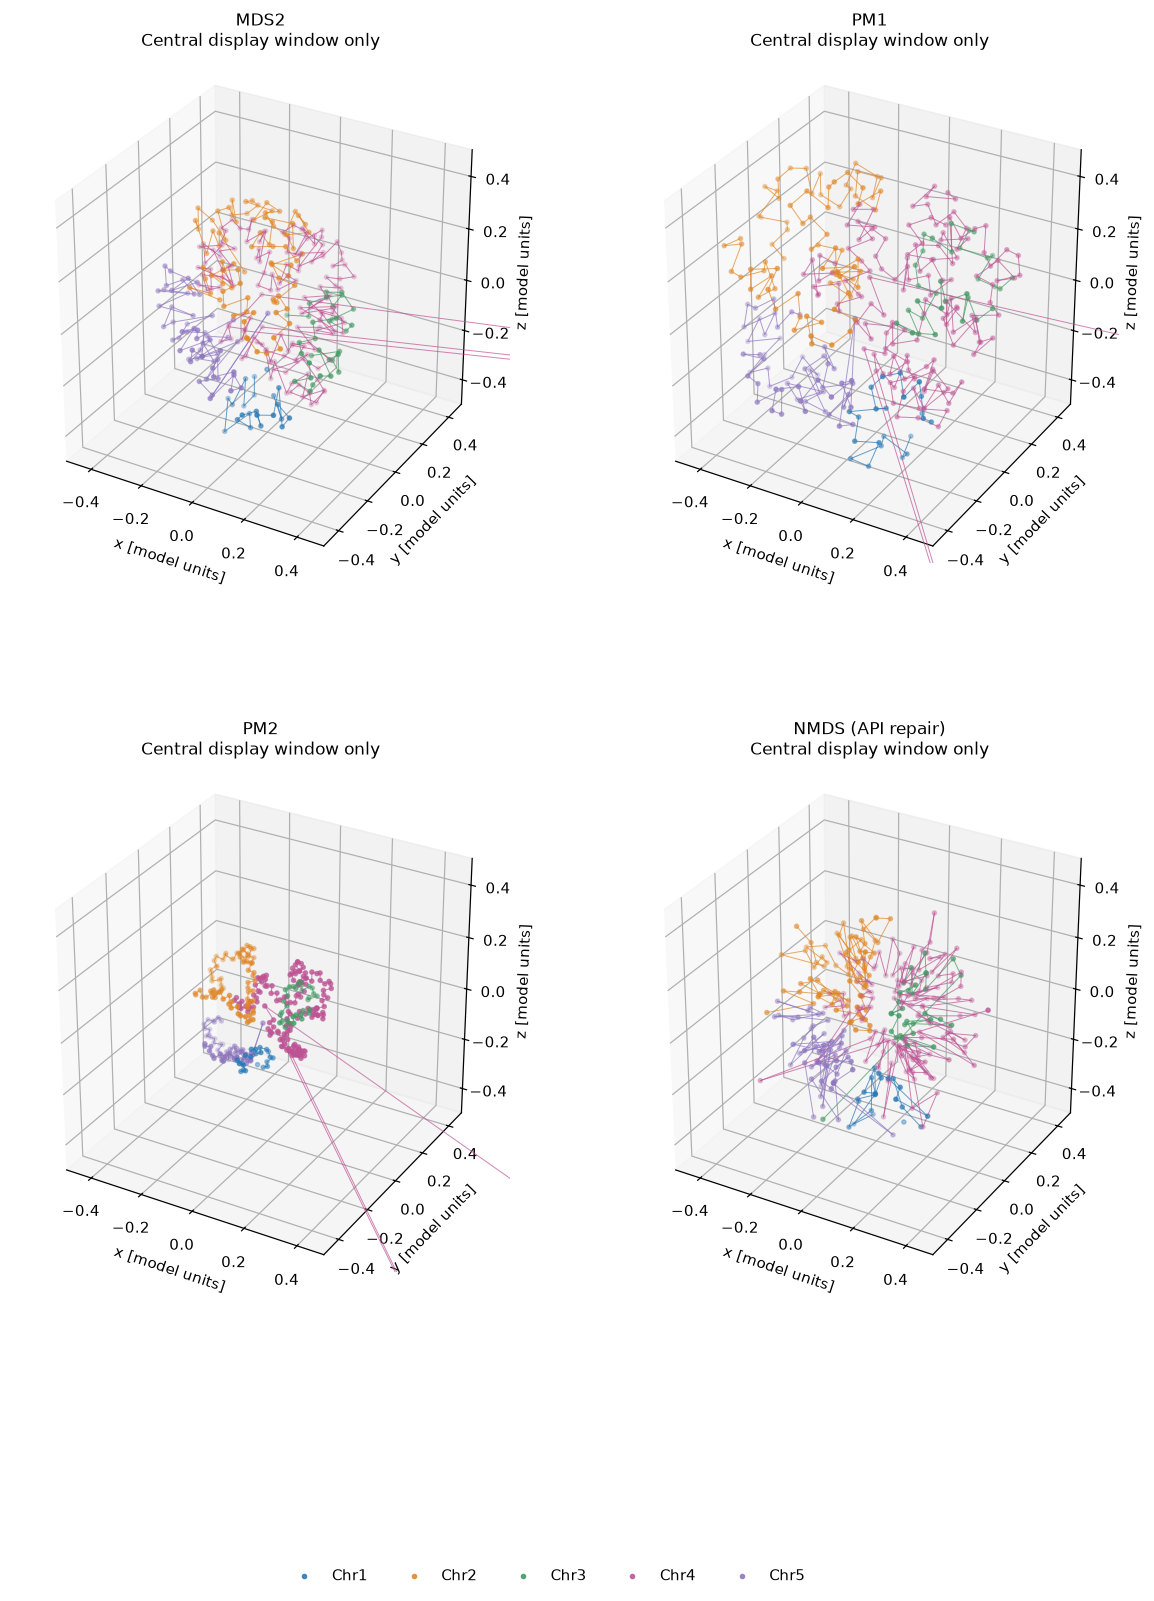

In [8]:
fig=plt.figure(figsize=(13,13));fig.subplots_adjust(hspace=.36,wspace=.22,bottom=.08,top=.94);zoom_arrays={};window_counts=[]
for k,(name,coordinates) in enumerate(methods.items()):
    aligned,scale=align_for_display(coordinates,x,support,allow_scale=name=='PM2')
    ax=draw_structure(fig.add_subplot(2,2,k+1,projection='3d'),aligned,support,chrom,name+'\nCentral display window only')
    ax.set_xlim(-.5,.5);ax.set_ylim(-.5,.5);ax.set_zlim(-.5,.5)
    contained=np.all(np.abs(aligned[support])<=.5,axis=1).sum();window_counts.append(int(contained));zoom_arrays['aligned_method'+str(k)]=aligned
print('Coordinates within display window (all343 still scored):',dict(zip(methods,window_counts)))
show(fig,'fig10_central_display_zoom',dict(**zoom_arrays,window_limits=np.array([-.5,.5]),visible_counts=np.array(window_counts),support=support,chromosome=chrom),'Supplementary display-only global coordinate window±0.5; full-support views in figures3/4 and all343 supported coordinates remain the scored domain. PM2 global scale display is declared.')

## 6. Conclusion and scope
The fresh local PM1 result is assessed against an independently executed author implementation, with all supported pair distances and an independent contact-loss check. Source PM2 and qualified API-repaired NMDS comparisons, count residuals, simulated coverage loss, genomic aggregation and contact-law sensitivity expose the distinction between numerical reproducibility and biological identifiability.

The inferred geometry is an ensemble consensus conditional on the power-law, visibility correction and positive-pair selection. Missing contacts, population heterogeneity, restriction/ligation biases and nonlinear local optima remain limitations. We do not claim nanometer accuracy, exact single-cell folding, known restriction-enzyme identity or sample-specific reproduction of the paper's mouse enzyme-replicate comparison. ChromSDE is historical context only: no runnable original result on this bound sample is available, so no fabricated bar or substituted geometry is presented. Earlier-backend results are archived diagnostics, not numerical acceptance evidence.

References: Varoquaux et al., *Bioinformatics*2014, doi:10.1093/bioinformatics/btu268; Duan et al., *Nature*2010, doi:10.1038/nature08973. BSD source notices and data-rights limitations are retained in NOTICE; detailed native-run provenance belongs to the maintainer validation record.

In [9]:
# Evaluate the fresh reconstruction using the standalone independent Judge.
import importlib.util
spec=importlib.util.spec_from_file_location('hic_notebook_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
output=ROOT/'output/reconstruction.npz';output.parent.mkdir(exist_ok=True);np.savez_compressed(output,reconstruction=fresh)
report,returncode=judge.evaluate(output);print(json.dumps(report,indent=2));assert returncode==0
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False))
experiment_summary=dict(primary_seconds=primary_seconds,pm2_seconds=pm2_seconds,nmds_seconds=nmds_seconds,primary_vs_original=geometry_metrics(x,source_pm1),pm2_vs_original=geometry_metrics(pm2,source_pm2),qualified_nmds_vs_original=geometry_metrics(nmds,source_nmds),poisson_deviances=deviances.tolist(),count_retention=thin_results,resolution=coarse_results,exponents=exponent_results,judge=report,environment=environment)
if FIGURE_DIR:
    (Path(FIGURE_DIR)/'experiment_summary.json').write_text(json.dumps(experiment_summary,indent=2,allow_nan=False))
print('All ten actual figure groups computed; final fresh primary submission judged:',report['status'])

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "distance_ncc": 0.9999999999999999,
    "distance_nrmse": 0.0,
    "relative_poisson_excess": 0.0
  },
  "thresholds": {
    "distance_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "distance_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "relative_poisson_excess": {
      "comparison": "<=",
      "boundary": 1e-05
    }
  },
  "errors": []
}
All ten actual figure groups computed; final fresh primary submission judged: pass
